In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import os
from sklearn.utils.class_weight import compute_sample_weight

In [2]:
df = pd.read_excel(r"C:\Users\hiteshree\Downloads\Silver_buy_sell_recommendation.xlsx")
print(df.head())

        Date  SILVER    GOLD  CRUDE OIL  DOLLAR     SP500   NIFTY50  FED RATE  \
0 2018-01-03   0.061  1318.5      61.63    92.16  2713.06  10443.20      1.42   
1 2018-01-04   0.002  1321.6      62.01    91.85  2723.99  10504.80      1.42   
2 2018-01-05   0.016  1322.3      61.44    91.95  2743.15  10558.85      1.42   
3 2018-01-08  -0.141  1320.4      61.73    92.36  2747.71  10623.60      1.42   
4 2018-01-09  -0.134  1313.7      62.96    92.53  2751.29  10637.00      1.42   

   BOND YIELD DECISION  
0       7.322      BUY  
1       7.331      BUY  
2       7.288      BUY  
3       7.344     SELL  
4       7.367     SELL  


In [3]:
df.shape

(1138, 10)

In [4]:
df = df.drop(columns =['Date'], axis=1)
df.head()

,SILVER,GOLD,CRUDE OIL,DOLLAR,SP500,NIFTY50,FED RATE,BOND YIELD,DECISION
0,0.061,1318.5,61.63,92.16,2713.06,10443.20,1.42,7.322,BUY
1,0.002,1321.6,62.01,91.85,2723.99,10504.80,1.42,7.331,BUY
2,0.016,1322.3,61.44,91.95,2743.15,10558.85,1.42,7.288,BUY
3,-0.141,1320.4,61.73,92.36,2747.71,10623.60,1.42,7.344,SELL
4,-0.134,1313.7,62.96,92.53,2751.29,10637.00,1.42,7.367,SELL


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1138 entries, 0 to 1137
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   SILVER      1138 non-null   float64
 1   GOLD        1138 non-null   float64
 2   CRUDE OIL   1138 non-null   float64
 3   DOLLAR      1138 non-null   float64
 4   SP500       1138 non-null   float64
 5   NIFTY50     1138 non-null   float64
 6   FED RATE    1138 non-null   float64
 7   BOND YIELD  1138 non-null   float64
 8   DECISION    1138 non-null   object 
dtypes: float64(8), object(1)
memory usage: 80.1+ KB


In [6]:
#Label Encoding:

from sklearn import preprocessing

 

colname = ['DECISION']
le = {}

for x in colname:

    le[x] = preprocessing.LabelEncoder()
for x in colname:
    print(le[x])
    df[x] = le[x].fit_transform(df[x])

LabelEncoder()


In [7]:
df['DECISION'].value_counts()

0    586
1    552
Name: DECISION, dtype: int64

# Univariate Analysis

In [8]:
df.describe()

,SILVER,GOLD,CRUDE OIL,DOLLAR,SP500,NIFTY50,FED RATE,BOND YIELD,DECISION
count,1138.000000,1138.000000,1138.000000,1138.000000,1138.000000,1138.000000,1138.000000,1138.000000,1138.000000
mean,0.006005,1610.573726,64.662425,96.649956,3444.050404,13288.610018,1.229376,6.818918,0.485062
std,0.449963,247.600986,19.979335,5.094213,665.450958,2902.183080,1.097472,0.684768,0.499997
min,-3.212000,1184.000000,-37.630000,88.590000,2237.400000,7610.250000,0.040000,5.760000,0.000000
25%,-0.166750,1331.200000,53.252500,93.012500,2841.202500,10890.625000,0.090000,6.182750,0.000000
50%,0.011500,1710.650000,63.180000,96.320000,3268.190000,11880.975000,1.540000,6.689000,0.000000
75%,0.175000,1814.100000,73.757500,98.257500,4014.910000,16239.587500,2.180000,7.431000,1.000000
max,2.504000,2069.400000,123.700000,114.110000,4796.560000,18812.500000,4.330000,8.182000,1.000000


SILVER           AxesSubplot(0.125,0.808774;0.227941x0.0712264)
GOLD          AxesSubplot(0.398529,0.808774;0.227941x0.0712264)
CRUDE OIL     AxesSubplot(0.672059,0.808774;0.227941x0.0712264)
DOLLAR           AxesSubplot(0.125,0.723302;0.227941x0.0712264)
SP500         AxesSubplot(0.398529,0.723302;0.227941x0.0712264)
NIFTY50       AxesSubplot(0.672059,0.723302;0.227941x0.0712264)
FED RATE          AxesSubplot(0.125,0.63783;0.227941x0.0712264)
BOND YIELD     AxesSubplot(0.398529,0.63783;0.227941x0.0712264)
DECISION       AxesSubplot(0.672059,0.63783;0.227941x0.0712264)
dtype: object

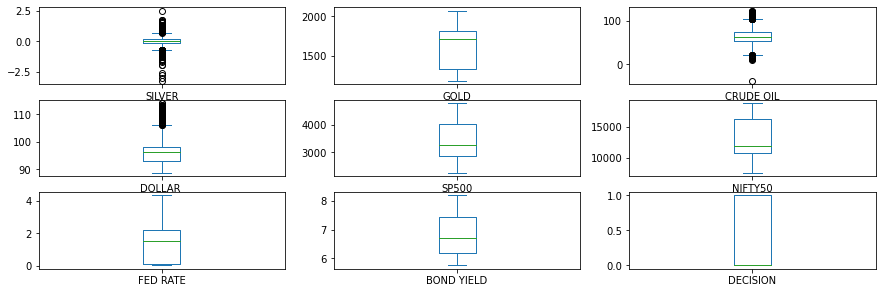

In [9]:
#BOX Plot

df.plot(kind = 'box',subplots = True, layout = (9,3), sharex = False, sharey = False, figsize = (15,15))

In [10]:
#Correlation
df.corr()

,SILVER,GOLD,CRUDE OIL,DOLLAR,SP500,NIFTY50,FED RATE,BOND YIELD,DECISION
SILVER,1.000000,0.046859,-0.029660,-0.006143,-0.004418,-0.013414,0.007316,-0.031534,-0.611331
GOLD,0.046859,1.000000,0.160357,0.091009,0.778695,0.610074,-0.625527,-0.712799,-0.058069
CRUDE OIL,-0.029660,0.160357,1.000000,0.387954,0.551991,0.717168,0.161933,0.427422,0.029078
DOLLAR,-0.006143,0.091009,0.387954,1.000000,0.108110,0.346647,0.513374,0.292013,0.016165
SP500,-0.004418,0.778695,0.551991,0.108110,1.000000,0.916827,-0.461630,-0.412426,-0.023541
NIFTY50,-0.013414,0.610074,0.717168,0.346647,0.916827,1.000000,-0.117622,-0.127145,-0.007759
FED RATE,0.007316,-0.625527,0.161933,0.513374,-0.461630,-0.117622,1.000000,0.717036,0.010185
BOND YIELD,-0.031534,-0.712799,0.427422,0.292013,-0.412426,-0.127145,0.717036,1.000000,0.068286
DECISION,-0.611331,-0.058069,0.029078,0.016165,-0.023541,-0.007759,0.010185,0.068286,1.000000


<AxesSubplot:>

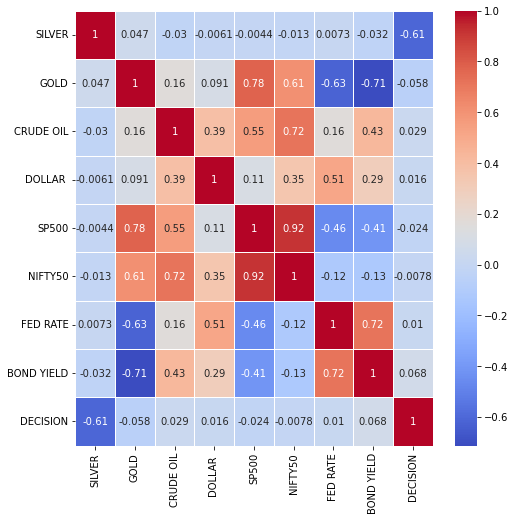

In [11]:
#HeatMap
plt.figure(figsize=(8, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", linecolor='white', linewidths=1)

In [12]:
Correlation_DF = df.corr()
Correlation_DF.head(9)

,SILVER,GOLD,CRUDE OIL,DOLLAR,SP500,NIFTY50,FED RATE,BOND YIELD,DECISION
SILVER,1.000000,0.046859,-0.029660,-0.006143,-0.004418,-0.013414,0.007316,-0.031534,-0.611331
GOLD,0.046859,1.000000,0.160357,0.091009,0.778695,0.610074,-0.625527,-0.712799,-0.058069
CRUDE OIL,-0.029660,0.160357,1.000000,0.387954,0.551991,0.717168,0.161933,0.427422,0.029078
DOLLAR,-0.006143,0.091009,0.387954,1.000000,0.108110,0.346647,0.513374,0.292013,0.016165
SP500,-0.004418,0.778695,0.551991,0.108110,1.000000,0.916827,-0.461630,-0.412426,-0.023541
NIFTY50,-0.013414,0.610074,0.717168,0.346647,0.916827,1.000000,-0.117622,-0.127145,-0.007759
FED RATE,0.007316,-0.625527,0.161933,0.513374,-0.461630,-0.117622,1.000000,0.717036,0.010185
BOND YIELD,-0.031534,-0.712799,0.427422,0.292013,-0.412426,-0.127145,0.717036,1.000000,0.068286
DECISION,-0.611331,-0.058069,0.029078,0.016165,-0.023541,-0.007759,0.010185,0.068286,1.000000


# Outlier Treatment

In [13]:
df.columns

Index(['SILVER', 'GOLD', 'CRUDE OIL', 'DOLLAR ', 'SP500', 'NIFTY50',
       'FED RATE', 'BOND YIELD', 'DECISION'],
      dtype='object')

In [16]:
Columns_list = ['SILVER','GOLD', 'CRUDE OIL', 'DOLLAR ', 'SP500', 'NIFTY50', 'FED RATE',
       'BOND YIELD', 'DECISION']

In [17]:
for col in Columns_list:            
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3-q1 #Interquartile range
    low  = q1-1.5*iqr #acceptable range
    high = q3+1.5*iqr #acceptable range
    # Upper Limit
    df[col]=np.where(df[col] > high,high,df[col])
    # Lower Limit
    df[col]=np.where(df[col] < low,low,df[col]) 

SILVER           AxesSubplot(0.125,0.808774;0.227941x0.0712264)
GOLD          AxesSubplot(0.398529,0.808774;0.227941x0.0712264)
CRUDE OIL     AxesSubplot(0.672059,0.808774;0.227941x0.0712264)
DOLLAR           AxesSubplot(0.125,0.723302;0.227941x0.0712264)
SP500         AxesSubplot(0.398529,0.723302;0.227941x0.0712264)
NIFTY50       AxesSubplot(0.672059,0.723302;0.227941x0.0712264)
FED RATE          AxesSubplot(0.125,0.63783;0.227941x0.0712264)
BOND YIELD     AxesSubplot(0.398529,0.63783;0.227941x0.0712264)
DECISION       AxesSubplot(0.672059,0.63783;0.227941x0.0712264)
dtype: object

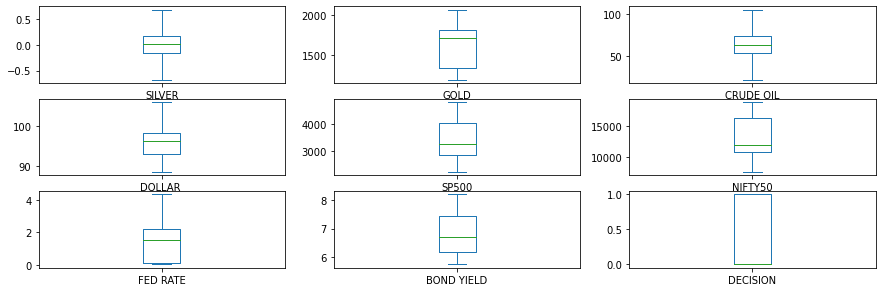

In [18]:
df.plot(kind = 'box',subplots = True, layout = (9,3), sharex = False, sharey = False, figsize = (15,15))

In [19]:
#df.dropna(inplace=True)
#df.shape

# Train test

In [20]:
X = df.drop(["DECISION"],axis=1)
Y = df["DECISION"]

In [21]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=.3,random_state=40)

print("Train Data Size - ",x_train.shape[0],'\n')
print("Test Data Size - ",x_test.shape[0],'\n')

Train Data Size -  796 

Test Data Size -  342 



In [22]:
scaler = StandardScaler()
scaler.fit(x_train)
x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

# Desicion Tree ID3


In [23]:
modCart = DecisionTreeClassifier()
param_grid = {"max_depth":np.arange(3,10)}
grids = GridSearchCV(modCart,param_grid)
grids.fit(x_train,y_train)
tree_preds = grids.predict_proba(x_test)[:,-1]
tree_performabce = roc_auc_score(y_test,tree_preds)

print("DecisionTree: Area under the ROC curve - {}".format(tree_performabce))

DecisionTree: Area under the ROC curve - 0.9683449054280535


In [24]:
grids.best_params_

{'max_depth': 3}

In [25]:
grids.cv_results_

{'mean_fit_time': array([0.00659537, 0.00579615, 0.00419598, 0.00695634, 0.00561852,
        0.00515876, 0.003936  ]),
 'std_fit_time': array([0.00272688, 0.0007473 , 0.00074774, 0.00661347, 0.00229119,
        0.00616671, 0.00605365]),
 'mean_score_time': array([0.00199986, 0.00139971, 0.00180011, 0.00020084, 0.00080075,
        0.00027084, 0.        ]),
 'std_score_time': array([0.00063113, 0.00079861, 0.00116521, 0.00040169, 0.00040038,
        0.00054169, 0.        ]),
 'param_max_depth': masked_array(data=[3, 4, 5, 6, 7, 8, 9],
              mask=[False, False, False, False, False, False, False],
        fill_value='?',
             dtype=object),
 'params': [{'max_depth': 3},
  {'max_depth': 4},
  {'max_depth': 5},
  {'max_depth': 6},
  {'max_depth': 7},
  {'max_depth': 8},
  {'max_depth': 9}],
 'split0_test_score': array([0.9625 , 0.9375 , 0.94375, 0.9375 , 0.925  , 0.93125, 0.93125]),
 'split1_test_score': array([0.96855346, 0.96226415, 0.96855346, 0.94339623, 0.94968553,
     

In [26]:
modCART = DecisionTreeClassifier(max_depth=3)
modCART.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=3)

In [27]:
fn = X.columns

In [28]:
def plot_roc_curve(true_y, y_prob):
    """
    plots the roc curve based of the probabilities
    """
    
    fpr, tpr, thresholds = roc_curve(true_y, y_prob)
    plt.plot(fpr, tpr)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

# Decision Tree Entropy Performance metrics on train data

In [29]:
y_train_pred = modCART.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))

[[406  11]
 [  9 370]]
              precision    recall  f1-score   support

         0.0       0.98      0.97      0.98       417
         1.0       0.97      0.98      0.97       379

    accuracy                           0.97       796
   macro avg       0.97      0.97      0.97       796
weighted avg       0.97      0.97      0.97       796

Accuracy is :  0.9748743718592965


model 2 AUC score: 0.9749372006352702


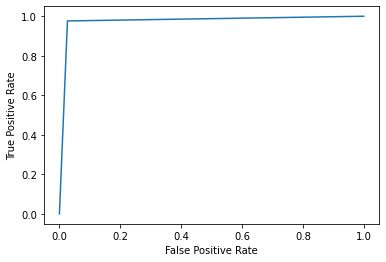

In [30]:
plot_roc_curve(y_train,y_train_pred)
print(f'model 2 AUC score: {roc_auc_score(y_train,y_train_pred)}')

# Decision Tree Entropy Performance metrics on test data

In [31]:
y_test_pred = modCART.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))

[[165   4]
 [  7 166]]
              precision    recall  f1-score   support

         0.0       0.96      0.98      0.97       169
         1.0       0.98      0.96      0.97       173

    accuracy                           0.97       342
   macro avg       0.97      0.97      0.97       342
weighted avg       0.97      0.97      0.97       342

Accuracy is :  0.9678362573099415


model 2 AUC score: 0.9679344666005404


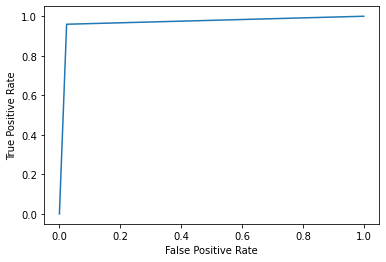

In [32]:
plot_roc_curve(y_test,y_test_pred)
print(f'model 2 AUC score: {roc_auc_score(y_test,y_test_pred)}')

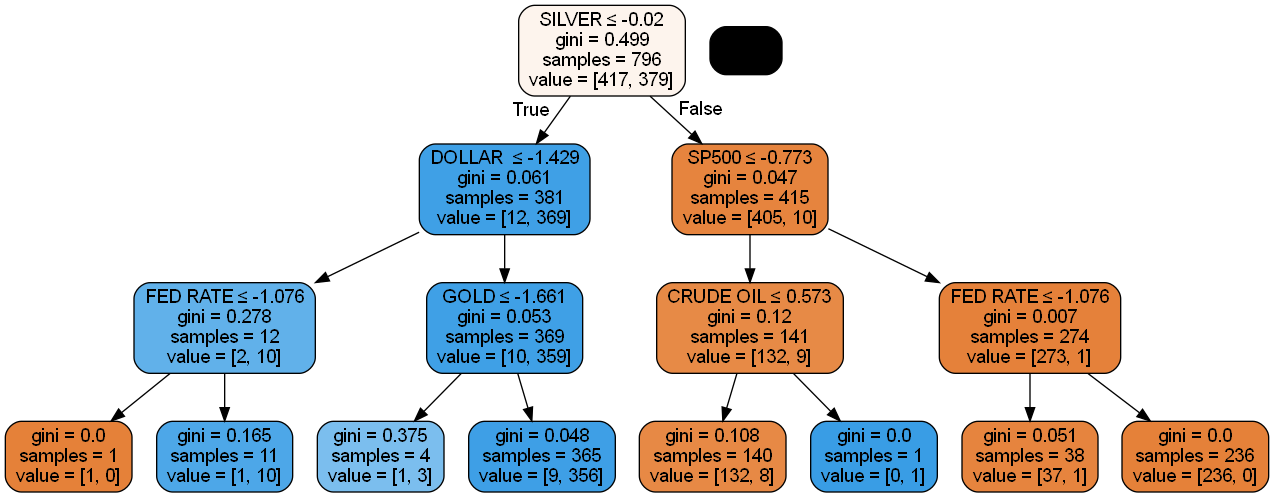

In [33]:
import graphviz
from six import StringIO
from  IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus
dot_data = StringIO()
export_graphviz(modCART,out_file=dot_data,filled=True,rounded=True,special_characters=True,feature_names=fn)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graphviz.Source(graph)
Image(graph.create_png())

# Decision Tree GINI Index

In [34]:
#modCart = DecisionTreeClassifier(criterion="gini")
#param_grid = {"max_depth":np.arange(3,10)}
#grids = GridSearchCV(modCart,param_grid)
#grids.fit(x_train,y_train)

modCart = DecisionTreeClassifier(criterion="gini")
param_grid = {"max_depth":np.arange(3,20)}
grids = GridSearchCV(modCart,param_grid)
grids.fit(x_train,y_train)
tree_preds = grids.predict_proba(x_test)[:,-1]
tree_performabce = roc_auc_score(y_test,tree_preds)

print("DecisionTree: Area under the ROC curve - {}".format(tree_performabce))


DecisionTree: Area under the ROC curve - 0.9722098710538016


In [35]:
grids.best_params_

{'max_depth': 3}

In [36]:
modCART = DecisionTreeClassifier(max_depth=5,criterion="gini")
modCART.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=5)

# Decision Tree GINI Index Performance metrics on train data

In [37]:
y_train_pred = modCART.predict(x_train)
print(pd.crosstab(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))

col_0     0.0  1.0
DECISION          
0.0       410    7
1.0         8  371
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98       417
         1.0       0.98      0.98      0.98       379

    accuracy                           0.98       796
   macro avg       0.98      0.98      0.98       796
weighted avg       0.98      0.98      0.98       796

Accuracy is :  0.9811557788944724


# Decision Tree GINI Index Performance metrics on test data

In [38]:
y_test_pred = modCART.predict(x_test)
print(pd.crosstab(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))

col_0     0.0  1.0
DECISION          
0.0       165    4
1.0        11  162
              precision    recall  f1-score   support

         0.0       0.94      0.98      0.96       169
         1.0       0.98      0.94      0.96       173

    accuracy                           0.96       342
   macro avg       0.96      0.96      0.96       342
weighted avg       0.96      0.96      0.96       342

Accuracy is :  0.956140350877193


In [39]:
fn = X.columns

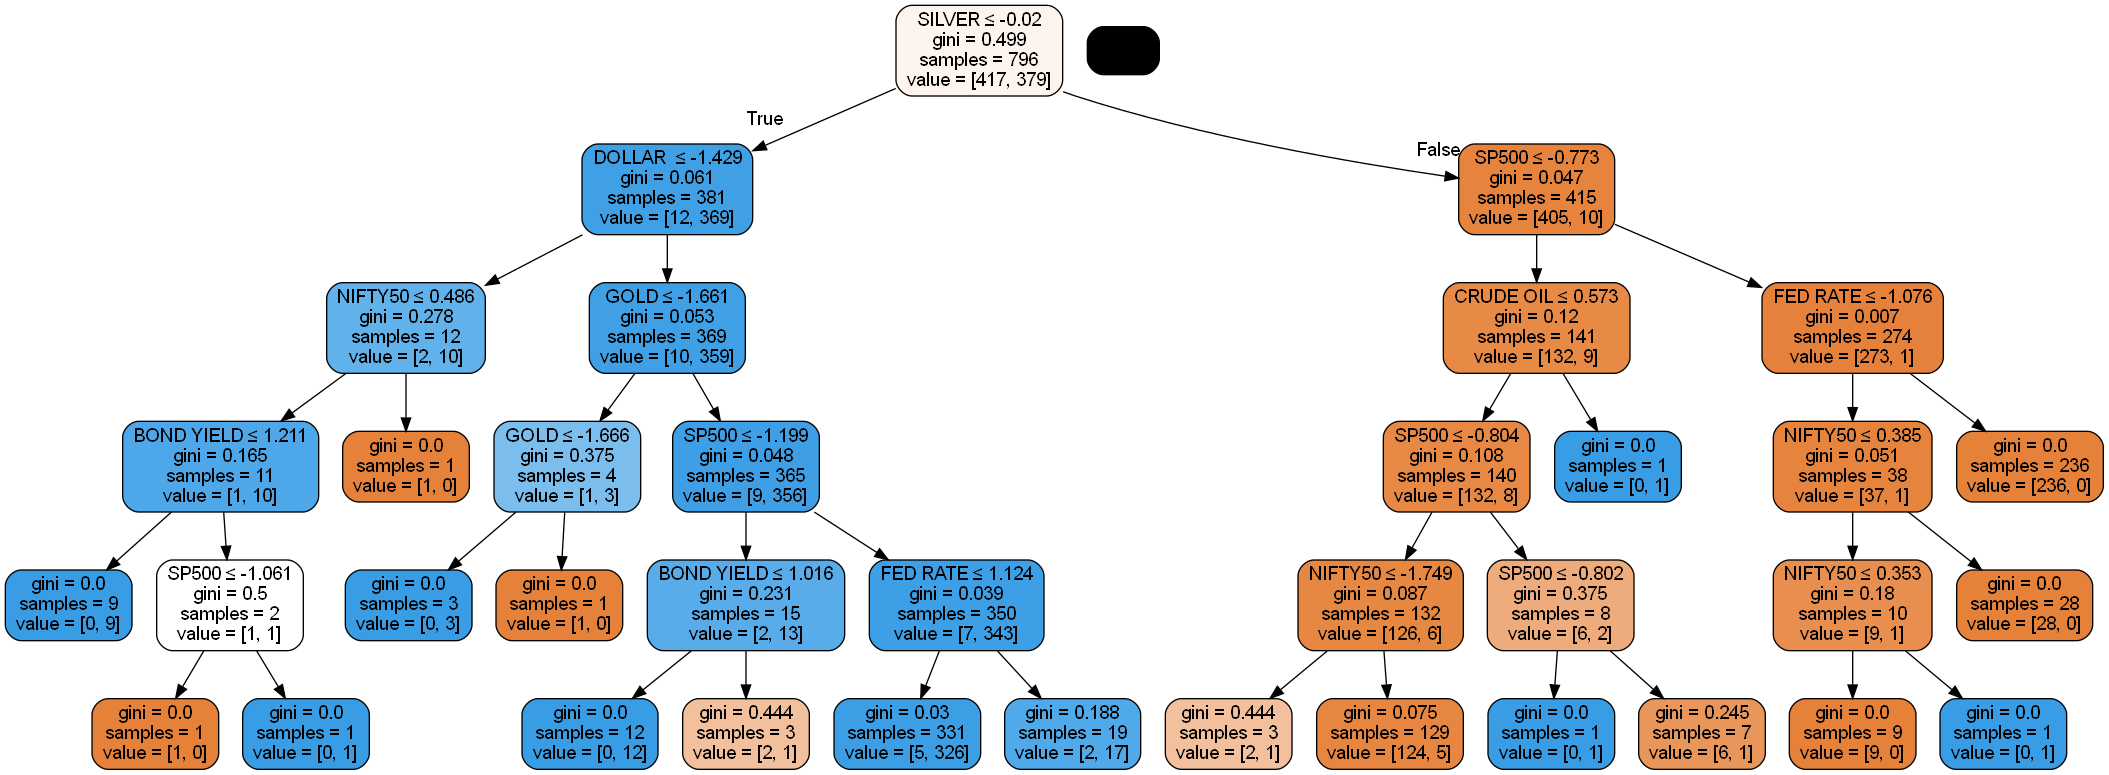

In [40]:
import graphviz
from six import StringIO
from  IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus
dot_data = StringIO()
export_graphviz(modCART,out_file=dot_data,filled=True,rounded=True,special_characters=True,feature_names = fn)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graphviz.Source(graph)
Image(graph.create_png())

# Random Forrest Entropy

In [41]:
rfc = RandomForestClassifier(n_estimators=15,criterion="entropy")
rfc.fit(x_train,y_train)

RandomForestClassifier(criterion='entropy', n_estimators=15)

# Random Forest Entropy Performance metrics on train data

In [42]:
y_train_pred2 = rfc.predict(x_train)
print(confusion_matrix(y_train,y_train_pred2))
print(classification_report(y_train,y_train_pred2))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred2))

[[416   1]
 [  0 379]]
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00       417
         1.0       1.00      1.00      1.00       379

    accuracy                           1.00       796
   macro avg       1.00      1.00      1.00       796
weighted avg       1.00      1.00      1.00       796

Accuracy is :  0.9987437185929648


# Random Forest Entropy Performance metrics on test data

In [43]:
y_test_pred2 = rfc.predict(x_test)
print(confusion_matrix(y_test,y_test_pred2))
print(classification_report(y_test,y_test_pred2))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred2))

[[165   4]
 [  8 165]]
              precision    recall  f1-score   support

         0.0       0.95      0.98      0.96       169
         1.0       0.98      0.95      0.96       173

    accuracy                           0.96       342
   macro avg       0.97      0.97      0.96       342
weighted avg       0.97      0.96      0.96       342

Accuracy is :  0.9649122807017544


# Random Forrest GINI Index

In [44]:
rfc = RandomForestClassifier(n_estimators=15,criterion="gini")
rfc.fit(x_train,y_train)

RandomForestClassifier(n_estimators=15)

# Random Forrest GINI Index Performance metrics on train data

In [45]:
y_train_pred2 = rfc.predict(x_train)
print(confusion_matrix(y_train,y_train_pred2))
print(classification_report(y_train,y_train_pred2))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred2))

[[416   1]
 [  2 377]]
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00       417
         1.0       1.00      0.99      1.00       379

    accuracy                           1.00       796
   macro avg       1.00      1.00      1.00       796
weighted avg       1.00      1.00      1.00       796

Accuracy is :  0.9962311557788944


# Gaussian Naive Bayes

In [46]:
model = GaussianNB()
model.fit(x_train,y_train)

GaussianNB()

# Naive Bayes Performance metrics on train data

In [47]:
y_train_pred = model.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))

[[397  20]
 [ 23 356]]
              precision    recall  f1-score   support

         0.0       0.95      0.95      0.95       417
         1.0       0.95      0.94      0.94       379

    accuracy                           0.95       796
   macro avg       0.95      0.95      0.95       796
weighted avg       0.95      0.95      0.95       796

Accuracy is :  0.9459798994974874


# Naive Bayes Performance metrics on test data

In [48]:
y_test_pred = model.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))

[[163   6]
 [ 19 154]]
              precision    recall  f1-score   support

         0.0       0.90      0.96      0.93       169
         1.0       0.96      0.89      0.92       173

    accuracy                           0.93       342
   macro avg       0.93      0.93      0.93       342
weighted avg       0.93      0.93      0.93       342

Accuracy is :  0.9269005847953217


# KNN

In [49]:
model = KNeighborsClassifier()
param_grid = {"n_neighbors":np.arange(3,10)}
grids = GridSearchCV(model,param_grid)
grids.fit(x_train,y_train)
knn_preds = grids.predict(x_test)
knn_performabce = accuracy_score(y_test,knn_preds)

print("KNN:accuracy - {}".format(knn_performabce))

KNN:accuracy - 0.9210526315789473


In [50]:
grids.best_params_

{'n_neighbors': 9}

In [51]:
model = KNeighborsClassifier(n_neighbors = 9)
model.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=9)

# KNN Performance metrics on train data

In [52]:
y_train_pred = model.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))

[[396  21]
 [ 25 354]]
              precision    recall  f1-score   support

         0.0       0.94      0.95      0.95       417
         1.0       0.94      0.93      0.94       379

    accuracy                           0.94       796
   macro avg       0.94      0.94      0.94       796
weighted avg       0.94      0.94      0.94       796

Accuracy is :  0.9422110552763819


# KNN Performance metrics on test data

In [53]:
y_test_pred = model.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))

[[160   9]
 [ 18 155]]
              precision    recall  f1-score   support

         0.0       0.90      0.95      0.92       169
         1.0       0.95      0.90      0.92       173

    accuracy                           0.92       342
   macro avg       0.92      0.92      0.92       342
weighted avg       0.92      0.92      0.92       342

Accuracy is :  0.9210526315789473


# SVM Classifier
1) Kernel = rbf

2) Kernel = Polynomial

In [54]:
# Building a Support Vector Machine on train data
svc_model = SVC(kernel='rbf', gamma=0.5, C=0.1)
svc_model.fit(x_train, y_train)

SVC(C=0.1, gamma=0.5)

# SVM Performance metrics on train data

In [55]:
y_train_pred = svc_model.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))

[[401  16]
 [ 24 355]]
              precision    recall  f1-score   support

         0.0       0.94      0.96      0.95       417
         1.0       0.96      0.94      0.95       379

    accuracy                           0.95       796
   macro avg       0.95      0.95      0.95       796
weighted avg       0.95      0.95      0.95       796

Accuracy is :  0.949748743718593


# SVM Performance metrics on test data

In [56]:
y_test_pred = svc_model.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))

[[162   7]
 [ 15 158]]
              precision    recall  f1-score   support

         0.0       0.92      0.96      0.94       169
         1.0       0.96      0.91      0.93       173

    accuracy                           0.94       342
   macro avg       0.94      0.94      0.94       342
weighted avg       0.94      0.94      0.94       342

Accuracy is :  0.935672514619883
